<a href="https://colab.research.google.com/github/noval110/MechineLearning_KNN/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as  np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns

df = pd.read_csv('drive/MyDrive/training/drug200.csv')
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


1.**Data Understanding**

In [7]:
print("data shape :", df.shape)

data shape : (200, 6)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [9]:
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [11]:
df.Drug.value_counts()

,count
Drug,
DrugY,91
drugX,54
drugA,23
drugC,16
drugB,16


In [12]:
df.Sex.value_counts()

,count
Sex,
M,104
F,96


<Axes: xlabel='Age', ylabel='Count'>

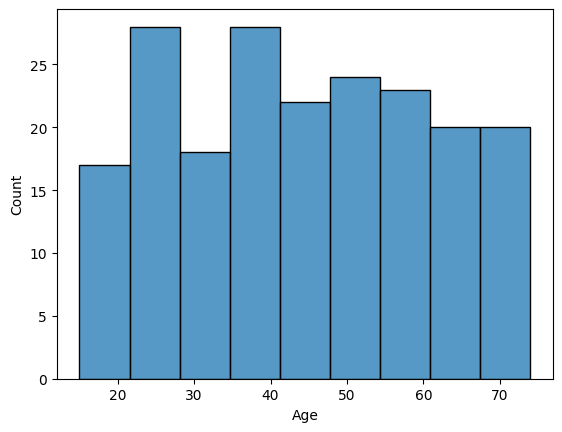

In [15]:
sns.histplot(df['Age'])

**2. Cleaning Data**

In [16]:
df.isnull().sum()

,0
Age,0
Sex,0
BP,0
Cholesterol,0
Na_to_K,0
Drug,0


# *Mencari Duplikasi Data*

In [18]:
df.duplicated().sum()

np.int64(0)

# **3. Exploratory Data Analysis(EDA)**

/tmp/ipykernel_2003/601668445.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Drug', data=df, palette='flare')


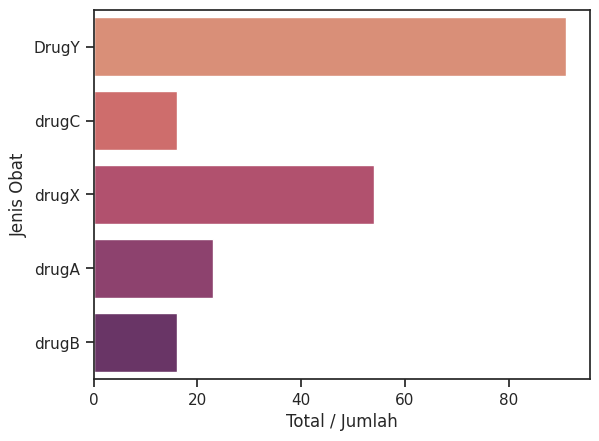

In [21]:
sns.set_theme(style='ticks')
sns.countplot(y='Drug', data=df, palette='flare')
plt.ylabel("Jenis Obat")
plt.xlabel('Total / Jumlah')
plt.show()

/tmp/ipykernel_2003/975575927.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df, palette='rocket')


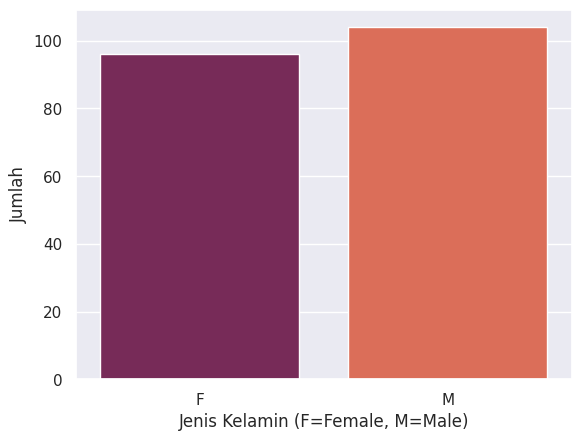

In [23]:
sns.set_theme(style='darkgrid')
sns.countplot(x='Sex', data=df, palette='rocket')
plt.ylabel("Jumlah")
plt.xlabel('Jenis Kelamin (F=Female, M=Male)')
plt.show()

# **Data Preparation**

In [24]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [30]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

df['Sex'] = label_encoder.fit_transform(df['Sex'])
df['BP'] = label_encoder.fit_transform(df['BP'])
df['Cholesterol'] = label_encoder.fit_transform(df['Cholesterol'])
df['Drug'] = label_encoder.fit_transform(df['Drug'])

In [31]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,0
1,47,1,1,0,13.093,3
2,47,1,1,0,10.114,3
3,28,0,2,0,7.798,4
4,61,0,1,0,18.043,0


# *Proses Spliting Data*

In [33]:
X = df.drop(columns = ['Drug'])
Y = df['Drug']

print("X :", X.shape)
print("Y :", Y.shape)

X : (200, 5)
Y : (200,)


In [34]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [36]:
print(f"x_train : {x_train.shape} ")
print(f"x_test : {x_test.shape} ")
print(f"y_train : {y_train.shape} ")
print(f"y_train : {y_test.shape} ")

x_train : (160, 5) 
x_test : (40, 5) 
y_train : (160,) 
y_train : (40,) 


# **5. Modeling**

In [40]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)
KNN_acc = accuracy_score(y_pred, y_test)

print(classification_report(y_test, y_pred))
print('Akurasi KNN : {:.2f}%'.format(KNN_acc*100))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.56      0.83      0.67         6
           2       0.50      0.67      0.57         3
           3       1.00      0.20      0.33         5
           4       0.73      0.73      0.73        11

    accuracy                           0.78        40
   macro avg       0.76      0.69      0.66        40
weighted avg       0.82      0.78      0.76        40

Akurasi KNN : 77.50%


In [43]:
testing = {'Age': [35],
           'Sex': [1],
           'BP': [2],
           'Cholesterol': [0],
           'Na_to_K': [4.5]
           }

testing = pd.DataFrame(testing)
testing

,Age,Sex,BP,Cholesterol,Na_to_K
0,35,1,2,0,4.5


In [45]:
pred_coba = knn.predict(testing)
print("Hasil Prediksi Dari Pasien Baru")
print(pred_coba)

Hasil Prediksi Dari Pasien Baru
[4]
